# Reproducing LITE: our runs vs the paper

We trained the paper's model, **plain LITE with the paper's settings**, on six UCR datasets, using several random seeds per dataset, on Kaggle (GPU T4). This notebook loads those trained models from `reproduction_models/`, runs them on each dataset's official test set, and compares the results with the numbers the LITE authors report.

- **Training settings (as in the paper):** 1500 epochs, Adam, learning rate halved after 50 epochs without improvement (minimum 1e-4), best checkpoint by training loss. Code: `run_ablation.py --conditions original`.
- **LITETime** is the paper's ensemble: the softmax outputs of 5 LITE models averaged. We build the same ensembles from our models.
- **Paper numbers** are read from the repo's `results.csv` (LITE, LITETime) and `results_ensemble_study.csv` (LITETime-k for k = 1–10).
- **Check:** section 4 compares the accuracy recomputed here with the accuracy logged when each model was trained.

Run from the `LITE-main` folder (Kernel → Restart & Run All). No training; a few minutes on CPU.

## 1. Setup

In [1]:
import itertools, sys, warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import tensorflow as tf
from sklearn.metrics import accuracy_score

warnings.filterwarnings("ignore")
tf.get_logger().setLevel("ERROR")
ROOT = Path.cwd()
sys.path.insert(0, str(ROOT))
from src.utils import load_data

MODELS = ROOT / "reproduction_models"
LOGS = ROOT / "experiment_results"
FIGS = LOGS / "figures"
FIGS.mkdir(parents=True, exist_ok=True)
DATASETS = ["Wine", "OliveOil", "ShapeletSim", "Beef", "PigAirwayPressure", "SemgHandMovementCh2"]

SURFACE, INK, INK2, GRID = "#fcfcfb", "#0b0b0b", "#52514e", "#e4e3df"
BLUE, PAPER = "#2a78d6", "#a3a29c"
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE, "font.size": 10,
    "text.color": INK, "axes.labelcolor": INK2, "xtick.color": INK2, "ytick.color": INK2, "axes.edgecolor": GRID,
    "axes.titlesize": 11, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.spines.top": False, "axes.spines.right": False,
})

## 2. What the paper reports

In [2]:
paper = pd.read_csv(ROOT / "results.csv").set_index("dataset")[["LITE", "LITETime"]] * 100
paper_k = pd.read_csv(ROOT / "results_ensemble_study.csv").set_index("dataset") * 100
display(paper.loc[DATASETS].round(1).rename(columns={"LITE": "paper LITE (%)", "LITETime": "paper LITETime (%)"}))

,paper LITE (%),paper LITETime (%)
dataset,,
Wine,64.1,66.7
OliveOil,69.3,80.0
ShapeletSim,73.8,75.0
Beef,72.0,76.7
PigAirwayPressure,34.7,47.1
SemgHandMovementCh2,47.9,51.1


## 3. Run our trained models on the test sets

In [3]:
DATA = {d: load_data(file_name=d) for d in DATASETS}
PROBS = {}  # dataset -> {seed: test-set softmax outputs}
for d in DATASETS:
    x_test = DATA[d][2]
    PROBS[d] = {}
    for path in sorted((MODELS / d).glob("seed_*.keras"), key=lambda p: int(p.stem[5:])):
        model = tf.keras.models.load_model(path, compile=False)
        PROBS[d][int(path.stem[5:])] = model.predict(x_test, verbose=0)
        tf.keras.backend.clear_session()

def acc(d, probs):
    return 100 * accuracy_score(DATA[d][3], np.mean(probs, 0).argmax(1))

per_seed = pd.DataFrame([{"dataset": d, "seed": s, "test accuracy (%)": acc(d, [p])}
                         for d in DATASETS for s, p in PROBS[d].items()])
info = pd.DataFrame({d: {"train series": len(DATA[d][1]), "test series": len(DATA[d][3]),
                         "classes": len(np.unique(DATA[d][1])), "length": DATA[d][0].shape[1],
                         "models": len(PROBS[d])} for d in DATASETS}).T
display(info)
display(per_seed.pivot(index="seed", columns="dataset", values="test accuracy (%)")[DATASETS].round(1))

,train series,test series,classes,length,models
Wine,57,54,2,234,5
OliveOil,30,30,4,570,5
ShapeletSim,20,180,2,500,5
Beef,30,30,5,470,10
PigAirwayPressure,104,208,52,2000,10
SemgHandMovementCh2,450,450,6,1500,3


dataset,Wine,OliveOil,ShapeletSim,Beef,PigAirwayPressure,SemgHandMovementCh2
seed,,,,,,
0,64.8,73.3,69.4,73.3,37.5,45.8
1,68.5,80.0,68.3,70.0,39.4,45.3
2,55.6,50.0,73.3,66.7,6.7,44.2
3,66.7,73.3,70.6,76.7,8.7,NaN
4,77.8,70.0,75.6,73.3,34.1,NaN
5,NaN,NaN,NaN,76.7,42.8,NaN
6,NaN,NaN,NaN,70.0,46.6,NaN
7,NaN,NaN,NaN,76.7,37.0,NaN
8,NaN,NaN,NaN,76.7,39.9,NaN


## 4. Check: recomputed accuracy vs the training-run logs

Each training run logged its test accuracy in a CSV (`experiment_results/`). Recomputing it from the saved model should give the same number. Kaggle kept the SemgHand models only for seeds 0–2; seeds 3–4 appear in the log only.

In [4]:
logs = pd.concat([
    pd.read_csv(LOGS / "reproduction_wine_oliveoil_kaggle" / "all_runs.csv"),
    pd.read_csv(LOGS / "shapelet_first_difference_kaggle" / "all_runs.csv"),
    pd.read_csv(LOGS / "ensemble_beef_pig_kaggle" / "all_runs.csv"),
    pd.read_csv(LOGS / "augment_1500ep_kaggle" / "all_results.csv"),
    pd.read_csv(LOGS / "semghand_1500ep_seeds_0_4" / "results_per_run.csv").query("machine == 'kaggle'"),
], ignore_index=True)
logs = logs[(logs.condition == "original") & logs.dataset.isin(DATASETS)].drop_duplicates(["dataset", "seed"])
logs = logs.assign(**{"logged accuracy (%)": logs.accuracy * 100, "training minutes (T4)": logs.training_seconds / 60})
check = logs[["dataset", "seed", "logged accuracy (%)", "training minutes (T4)"]].merge(per_seed, on=["dataset", "seed"], how="left")
check["match"] = np.where(check["test accuracy (%)"].isna(), "no saved model",
                          np.where((check["test accuracy (%)"] - check["logged accuracy (%)"]).abs() < 1e-6, "yes", "NO"))
display(check.sort_values(["dataset", "seed"]).round(2).set_index(["dataset", "seed"]))
print("models whose recomputed accuracy differs from the log:", (check.match == "NO").sum())

logged accuracy (%)  training minutes (T4)  \
dataset             seed                                               
Beef                0                   73.33                   5.23   
                    1                   70.00                   4.70   
                    2                   66.67                   5.21   
                    3                   76.67                   4.90   
                    4                   73.33                   5.10   
                    5                   76.67                   4.96   
                    6                   70.00                   5.25   
                    7                   76.67                   5.33   
                    8                   76.67                   4.67   
                    9                   76.67                   4.94   
OliveOil            0                   73.33                   3.12   
                    1                   80.00                   3.24   
                    2                   50.00                   3.34   
                    3                   73.33                   3.14   
                    4                   70.00                   3.47   
PigAirwayPressure   0                   37.50                   9.81   
                    1                   39.42                   9.50   
                    2                    6.73                   9.12   
                    3                    8.65                   9.50   
                    4                   34.13                   9.92   
                    5                   42.79                   9.52   
                    6                   46.63                   9.44   
                    7                   37.02                   9.07   
                    8                   39.90                   9.86   
                    9                   36.54                   9.38   
SemgHandMovementCh2 0                   45.78                  24.30   
                    1                   45.33                  23.12   
                    2                   44.22                  25.12   
                    3                   51.11                  23.98   
                    4                   47.56                  23.27   
ShapeletSim         0                   69.44                   5.37   
                    1                   68.33                   5.48   
                    2                   73.33                   5.43   
                    3                   70.56                   5.38   
                    4                   75.56                   5.30   
Wine                0                   64.81                   3.67   
                    1                   68.52                   3.26   
                    2                   55.56                   3.44   
                    3                   66.67                   3.77   
                    4                   77.78                   3.86   

                          test accuracy (%)           match  
dataset             seed                                     
Beef                0                 73.33             yes  
                    1                 70.00             yes  
                    2                 66.67             yes  
                    3                 76.67             yes  
                    4                 73.33             yes  
                    5                 76.67             yes  
                    6                 70.00             yes  
                    7                 76.67             yes  
                    8                 76.67             yes  
                    9                 76.67             yes  
OliveOil            0                 73.33             yes  
                    1                 80.00             yes  
                    2                 50.00             yes  
                    3                 73.33             yes  
         

models whose recomputed accuracy differs from the log: 0


## 5. Our reproduction vs the paper

- **Single LITE:** mean over seeds (from the logs, so SemgHand includes all 5 seeds), and its range.
- **LITETime (5 models):** for datasets with more than 5 models, the mean over every 5-model ensemble; SemgHand has 3 saved models, so it is compared with the paper's LITETime-3.

In [5]:
rows = []
for d in DATASETS:
    singles = logs.loc[logs.dataset == d, "logged accuracy (%)"]
    seeds = sorted(PROBS[d])
    k = min(5, len(seeds))
    ens = np.mean([acc(d, [PROBS[d][seeds[i]] for i in c]) for c in itertools.combinations(range(len(seeds)), k)])
    paper_ens = paper.loc[d, "LITETime"] if k == 5 else paper_k.loc[d, f"LITETime-{k}"]
    n_test = len(DATA[d][3])
    rows.append({"dataset": d, "seeds": len(singles),
                 "ours: LITE mean": singles.mean(), "ours: LITE min": singles.min(), "ours: LITE max": singles.max(),
                 "paper LITE": paper.loc[d, "LITE"],
                 "ensemble size": k, "ours: LITETime": ens, "paper LITETime": paper_ens,
                 "LITETime gap (test series)": round((ens - paper_ens) / 100 * n_test, 1) + 0.0})  # + 0.0: no "-0.0"
summary = pd.DataFrame(rows).set_index("dataset")
summary.round(2).to_csv(LOGS / "reproduction_summary_computed.csv")
display(summary.round(1))

,seeds,ours: LITE mean,ours: LITE min,ours: LITE max,paper LITE,ensemble size,ours: LITETime,paper LITETime,LITETime gap (test series)
dataset,,,,,,,,,
Wine,5,66.7,55.6,77.8,64.1,5,66.7,66.7,0.0
OliveOil,5,69.3,50.0,80.0,69.3,5,73.3,80.0,-2.0
ShapeletSim,5,71.4,68.3,75.6,73.8,5,77.2,75.0,4.0
Beef,10,73.7,66.7,76.7,72.0,5,74.5,76.7,-0.7
PigAirwayPressure,10,32.9,6.7,46.6,34.7,5,46.6,47.1,-1.2
SemgHandMovementCh2,5,46.8,44.2,51.1,47.9,3,50.0,51.4,-6.2


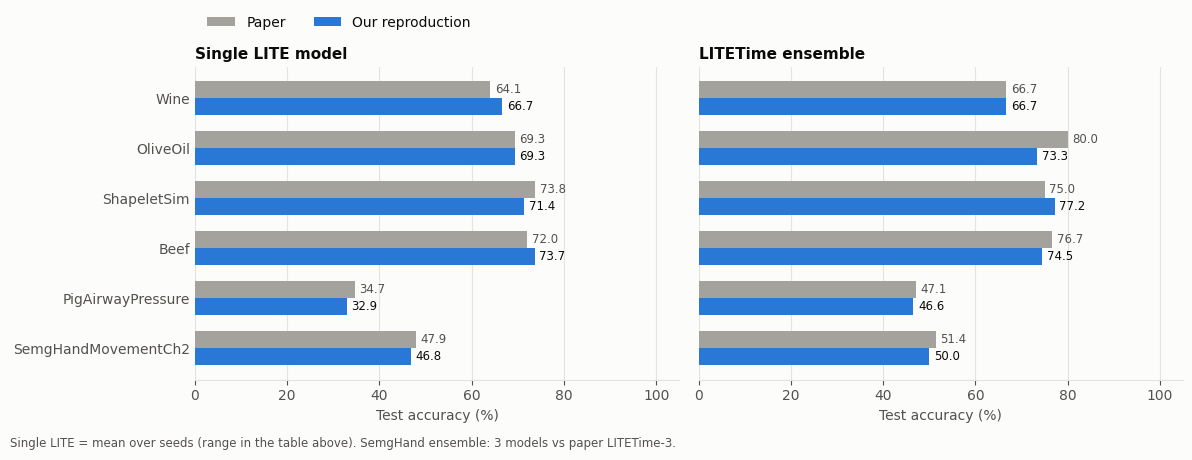

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.6), sharey=True)
y = np.arange(len(DATASETS))[::-1]
for ax, ours, theirs, title in [
        (axes[0], "ours: LITE mean", "paper LITE", "Single LITE model"),
        (axes[1], "ours: LITETime", "paper LITETime", "LITETime ensemble")]:
    ax.barh(y + 0.17, summary.loc[DATASETS, theirs], 0.34, color=PAPER, label="Paper")
    ax.barh(y - 0.17, summary.loc[DATASETS, ours], 0.34, color=BLUE, label="Our reproduction")
    for yi, d in zip(y, DATASETS):
        ax.text(summary.loc[d, theirs] + 1, yi + 0.17, f"{summary.loc[d, theirs]:.1f}", va="center", fontsize=8.5, color=INK2)
        ax.text(summary.loc[d, ours] + 1, yi - 0.17, f"{summary.loc[d, ours]:.1f}", va="center", fontsize=8.5, color=INK)
    ax.set_title(title)
    ax.set_xlim(0, 105)
    ax.set_xlabel("Test accuracy (%)")
    ax.xaxis.grid(True, color=GRID, lw=0.8)
    ax.set_axisbelow(True)
    ax.spines["left"].set_visible(False)
    ax.tick_params(axis="y", length=0)
axes[0].set_yticks(y, DATASETS)
axes[0].legend(loc="lower left", bbox_to_anchor=(0, 1.08), ncol=2, frameon=False)
fig.text(0.01, 0.01, "Single LITE = mean over seeds (range in the table above). SemgHand ensemble: 3 models vs paper LITETime-3.", fontsize=8.5, color=INK2)
fig.tight_layout(rect=(0, 0.03, 1, 1))
fig.savefig(FIGS / "reproduction_vs_paper.png", dpi=150)
plt.show()

## 6. Ensemble size: our curve vs the paper's LITETime-k

For each k, our accuracy is the mean over every possible ensemble of k of our models.

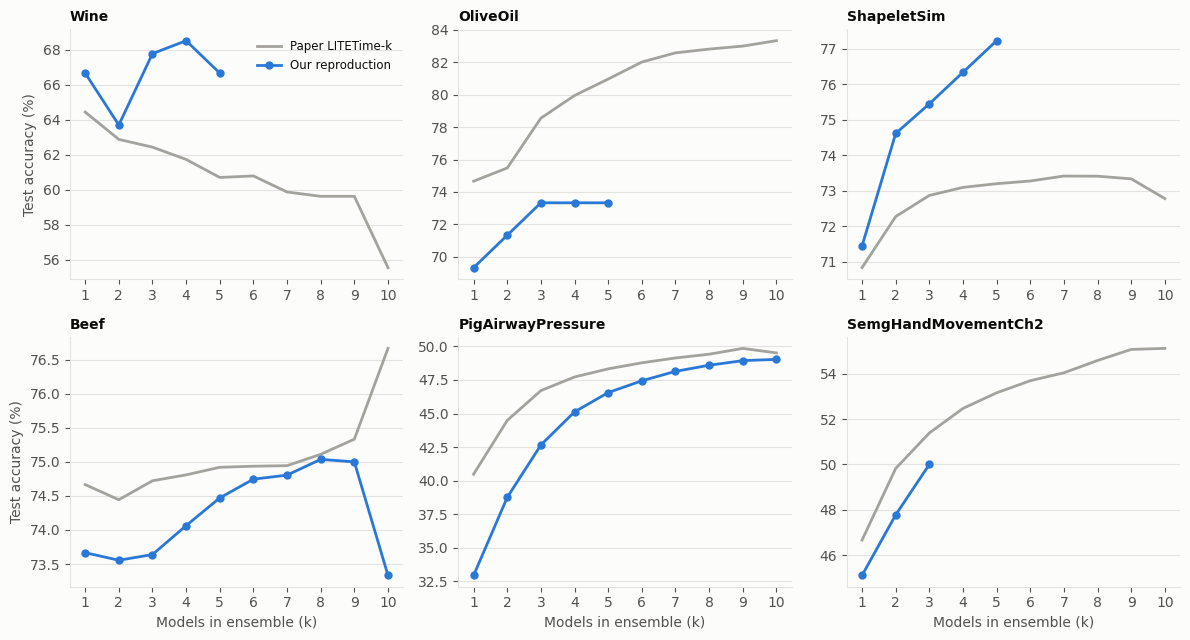

In [7]:
fig, axes = plt.subplots(2, 3, figsize=(12, 6.5))
for ax, d in zip(axes.flat, DATASETS):
    seeds = sorted(PROBS[d])
    ks = list(range(1, len(seeds) + 1))
    ours = [np.mean([acc(d, [PROBS[d][seeds[i]] for i in c]) for c in itertools.combinations(range(len(seeds)), k)]) for k in ks]
    ax.plot(range(1, 11), paper_k.loc[d].values, color=PAPER, lw=2, label="Paper LITETime-k")
    ax.plot(ks, ours, color=BLUE, lw=2, marker="o", ms=5, label="Our reproduction")
    ax.set_title(d, fontsize=10)
    ax.set_xticks(range(1, 11))
    ax.yaxis.grid(True, color=GRID, lw=0.8)
    ax.set_axisbelow(True)
for ax in axes[1]:
    ax.set_xlabel("Models in ensemble (k)")
for ax in axes[:, 0]:
    ax.set_ylabel("Test accuracy (%)")
axes[0, 0].legend(frameon=False, fontsize=8.5)
fig.tight_layout()
fig.savefig(FIGS / "reproduction_ensemble_curves.png", dpi=150)
plt.show()

## 7. Summary

Printed from the computed table above.

In [8]:
for d, r in summary.iterrows():
    print(f"{d:20s} single LITE {r['ours: LITE mean']:5.1f}% (paper {r['paper LITE']:.1f}%)   "
          f"LITETime-{int(r['ensemble size'])} {r['ours: LITETime']:5.1f}% (paper {r['paper LITETime']:.1f}%, "
          f"{r['LITETime gap (test series)']:+.1f} test series)")

Wine                 single LITE  66.7% (paper 64.1%)   LITETime-5  66.7% (paper 66.7%, +0.0 test series)
OliveOil             single LITE  69.3% (paper 69.3%)   LITETime-5  73.3% (paper 80.0%, -2.0 test series)
ShapeletSim          single LITE  71.4% (paper 73.8%)   LITETime-5  77.2% (paper 75.0%, +4.0 test series)
Beef                 single LITE  73.7% (paper 72.0%)   LITETime-5  74.5% (paper 76.7%, -0.7 test series)
PigAirwayPressure    single LITE  32.9% (paper 34.7%)   LITETime-5  46.6% (paper 47.1%, -1.2 test series)
SemgHandMovementCh2  single LITE  46.8% (paper 47.9%)   LITETime-3  50.0% (paper 51.4%, -6.2 test series)
